# Validate spectra (buoy vs reconstruction)

Compare **observed buoy spectra** to reconstructed metamodel spectra:

- **Buoy** — processed NetCDF (`Efth` on native freq/dir grid)
- **Bulk reconstruct** — `mm.reconstruct(..., spectral=False)` + `save_spectra`
- **Partition reconstruct** — `mm.reconstruct(..., spectral=True)` (WHACS partitions 0–3 summed)

Plots: ~12 random hourly timesteps, monthly mean, and seasonal mean for the selected
`period`.

**Prerequisites:** spectra caches under `tmp/reconstruct/` for the same `period`,
`sites`, and `mda_n` (`save_spectra: true` in `Samoa.json`).

In [1]:
import numpy as np
import xarray as xr
from IPython.display import display
from bluemath_tk.core.plotting.spectra import plot_spectrum_comparison
from utils.config import resolve
from utils import metamodel as mm
from utils import onshore_sites as obs


## Configuration

In [2]:
period = "2020-01"
period_label = period
offshore_name = "WHACS"
mda_n = 450
pca_variance = 0.99
wl = 0.0
goals = None  # all goals

buoy_instruments = ["Aunuu_Buoy"]
sites = [obs.snapwave_site_id(iid) for iid in buoy_instruments]
site_id = sites[0]

buoy_raw_files = {
    obs.snapwave_site_id("Aunuu_Buoy"): (
        "inputs/Observations/processed/buoy_Anuu_with_spectra.nc"
    ),
}

n_random = 12
random_seed = 42

recon_kw = dict(
    n=mda_n,
    offshore_name=offshore_name,
    goals=goals,
    wl=wl,
    site_ids=sites,
    pca_variance=pca_variance,
)

print("Observations JSON:", obs.geojson_path())
print(f"period   : {period_label}")
print(f"site     : {site_id}")


Observations JSON: /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Observations/Samoa_observations.json
period   : 2020-01
site     : buoy_Aunuu_Buoy


## 1 · Load spectra

In [3]:
buoy_raw = xr.open_dataset(resolve(buoy_raw_files[site_id])).sel(time=period)
spec_var = "Efth" if "Efth" in buoy_raw else "efth"
buoy_efth = buoy_raw[spec_var]

# Reconstruct with save_spectra=True first, rather than only trying to load
# an existing cache — makes this notebook runnable standalone instead of
# erroring out asking the user to run mm.reconstruct() by hand first.
reconstruct_kw = dict(
    n=mda_n,
    offshore_name=offshore_name,
    goals=goals,
    wl=wl,
    sites=sites,
    pca_variance=pca_variance,
)
mm.reconstruct(period, spectral=False, save_spectra=True, **reconstruct_kw)
mm.reconstruct(period, spectral=True, save_spectra=True, **reconstruct_kw)

bulk_spec = mm.load_reconstruction_spectra(
    period, spectral=False, load=False, **recon_kw
)
part_spec = mm.load_reconstruction_spectra(
    period, spectral=True, load=False, **recon_kw
)

for label, ds in [("bulk", bulk_spec), ("partition", part_spec)]:
    if ds is None:
        raise FileNotFoundError(
            f"Missing {label} spectra cache for {period_label!r} — run "
            f"mm.reconstruct(..., spectral={label == 'partition'}, recompute=True) "
            "with save_spectra=true in Samoa.json."
        )

bulk_efth = bulk_spec["efth"].sel(sites=site_id)
part_efth = part_spec["efth"].sel(sites=site_id)

print(f"{site_id}: buoy={dict(buoy_efth.sizes)}  bulk={dict(bulk_efth.sizes)}  part={dict(part_efth.sizes)}")


buoy_Aunuu_Buoy: buoy={'time': 744, 'freq': 56, 'dir': 72}  bulk={'time': 744, 'freq': 29, 'dir': 72}  part={'time': 744, 'freq': 29, 'dir': 72}


## 2 · Helpers

In [4]:
def pick_random_time_index(n: int, n_time: int, seed: int) -> np.ndarray:
    """Sorted integer indices along ``time``."""
    rng = np.random.default_rng(seed)
    n_pick = min(n, n_time)
    return np.sort(rng.choice(n_time, size=n_pick, replace=False))


def monthly_mean_spectra(da: xr.DataArray) -> dict[str, xr.DataArray]:
    """One time-averaged spectrum per calendar month present, keyed ``month=N``.

    Groups by calendar month across every year in ``da`` (a climatology, not
    one panel per year-month) so this stays at 12 panels regardless of how
    many years ``period`` spans.
    """
    months = sorted({int(m) for m in da["time"].dt.month.values})
    return {
        f"month={month}": da.sel(time=da.time.dt.month == month).mean(
            "time", skipna=True
        )
        for month in months
    }


def seasonal_mean_spectra(da: xr.DataArray) -> dict[str, xr.DataArray]:
    """One time-averaged spectrum per season present, keyed ``season=DJF`` etc.

    Groups by season code across every year in ``da``, so this stays at (up
    to) 4 panels regardless of how many years ``period`` spans.
    """
    seasons = sorted({str(s) for s in da["time"].dt.season.values})
    return {
        f"season={season}": da.sel(time=da.time.dt.season == season).mean(
            "time", skipna=True
        )
        for season in seasons
    }


PANEL_LABELS = (
    "Buoy observed",
    "Reconstruction bulk (partition -1)",
    "Reconstruction spectral (partitions 0-3)",
)
# Every panel is plotted with wavespectra's default normalised=True (each
# spectrum independently scaled 0-1 by its own peak) so all 3 sources share
# one consistent colorbar label regardless of how their raw attrs word it.
CBAR_KWARGS = {"label": "Normalised energy density", "shrink": 0.8, "pad": 0.08}


def show_triplet(
    buoy_da: xr.DataArray | None,
    bulk_da: xr.DataArray | None,
    part_da: xr.DataArray | None,
    title: str,
) -> None:
    """Buoy / bulk / spectral, always 3 columns in that order, for one moment.

    Any source missing for this particular moment is skipped rather than
    plotted blank, but the other panels still show — and still say which
    one they are.
    """
    specs = [
        (label, da)
        for label, da in zip(PANEL_LABELS, (buoy_da, bulk_da, part_da), strict=True)
        if da is not None
    ]
    if not specs:
        print(f"{title}: nothing to plot (missing on all 3 sources)")
        return
    missing = [
        label
        for label, da in zip(PANEL_LABELS, (buoy_da, bulk_da, part_da), strict=True)
        if da is None
    ]
    print(f"— {title} —" + (f"  (missing: {', '.join(missing)})" if missing else ""))
    display(plot_spectrum_comparison(specs, cbar_kwargs=CBAR_KWARGS))


sample_idx = pick_random_time_index(n_random, buoy_efth.sizes["time"], random_seed)
sample_buoy = buoy_efth.isel(time=sample_idx).load()
sample_bulk = bulk_efth.sel(time=sample_buoy.time.values).load()
sample_part = part_efth.sel(time=sample_buoy.time.values).load()

print(f"{site_id}: random sample {len(sample_idx)} timesteps (seed={random_seed})")


buoy_Aunuu_Buoy: random sample 12 timesteps (seed=42)


## 3 · Random timesteps (~24)

Independent draws on a shared hourly time axis (buoy and reconstruction times match).

— buoy_Aunuu_Buoy — 2020-01-03T15 —


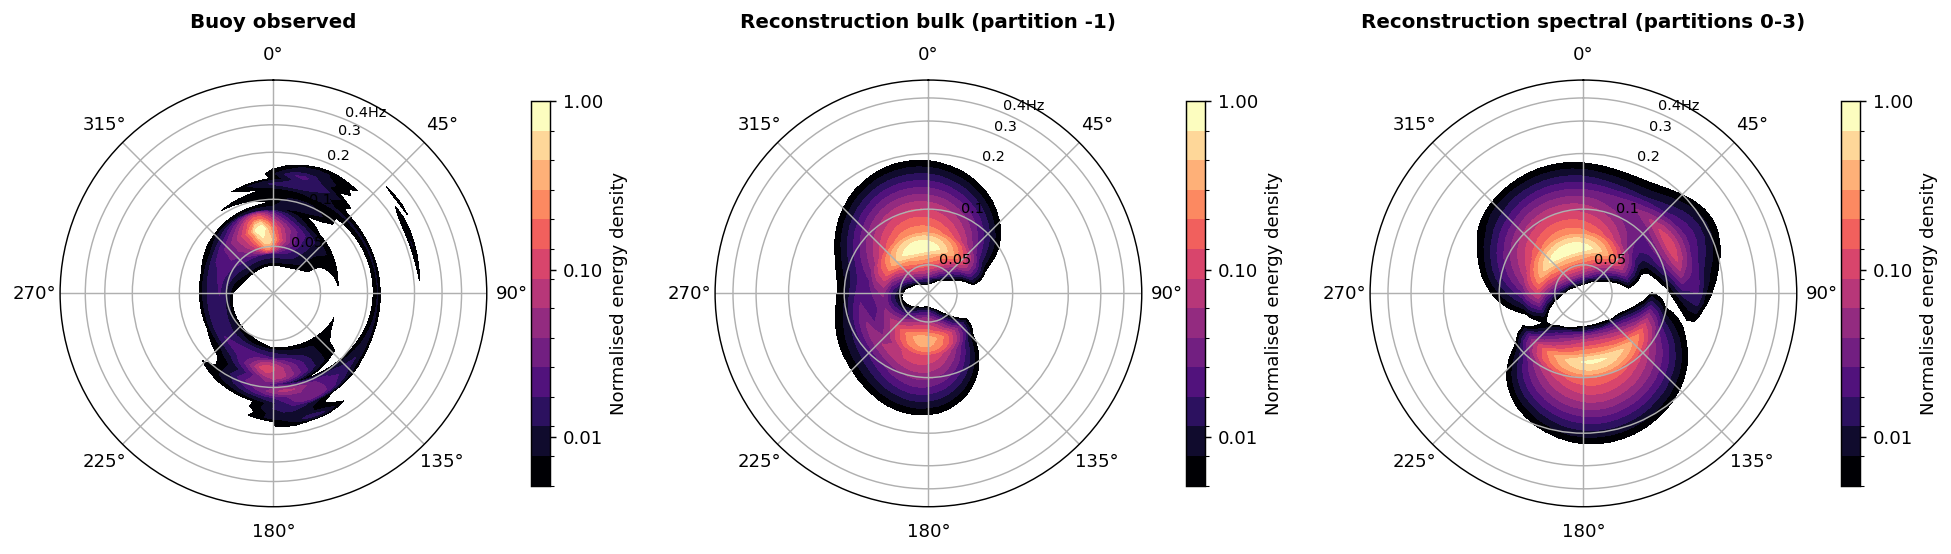

— buoy_Aunuu_Buoy — 2020-01-03T17 —


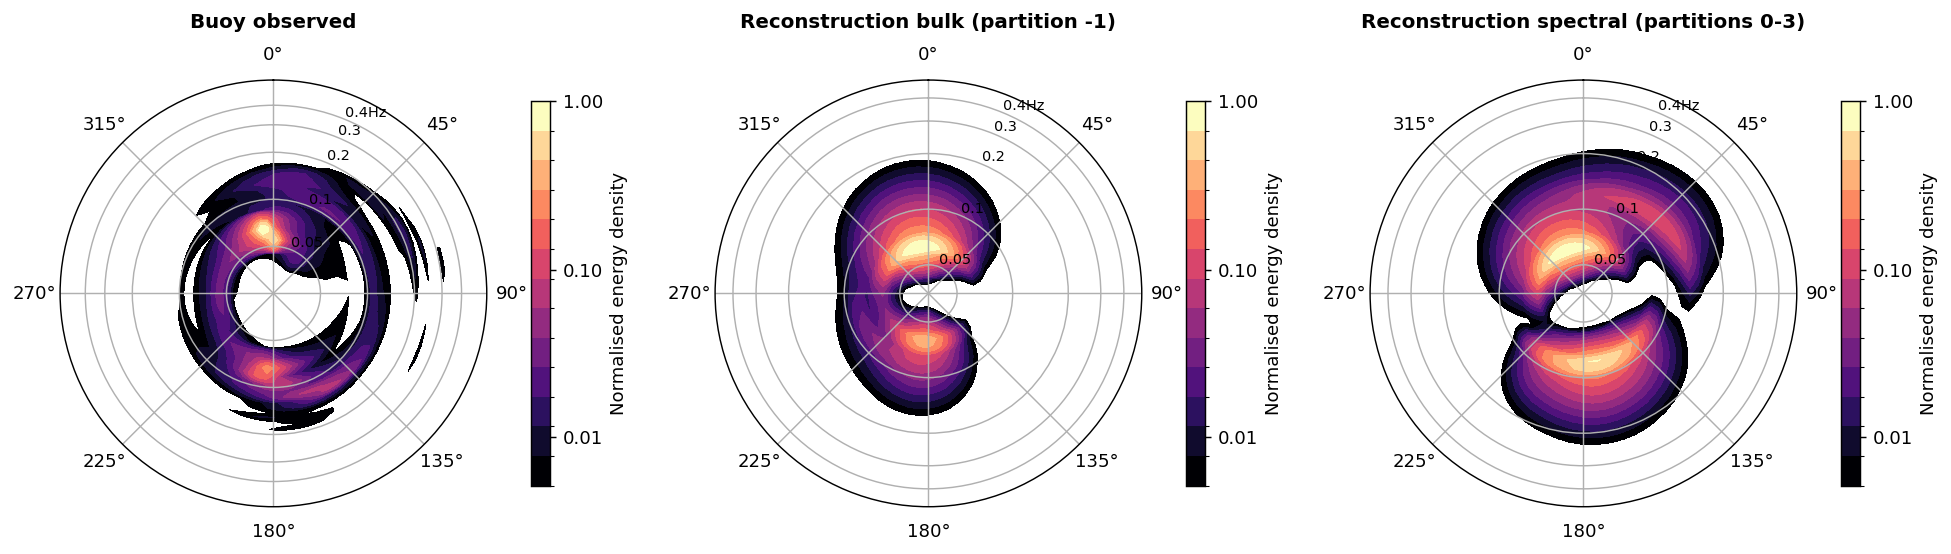

— buoy_Aunuu_Buoy — 2020-01-03T21 —


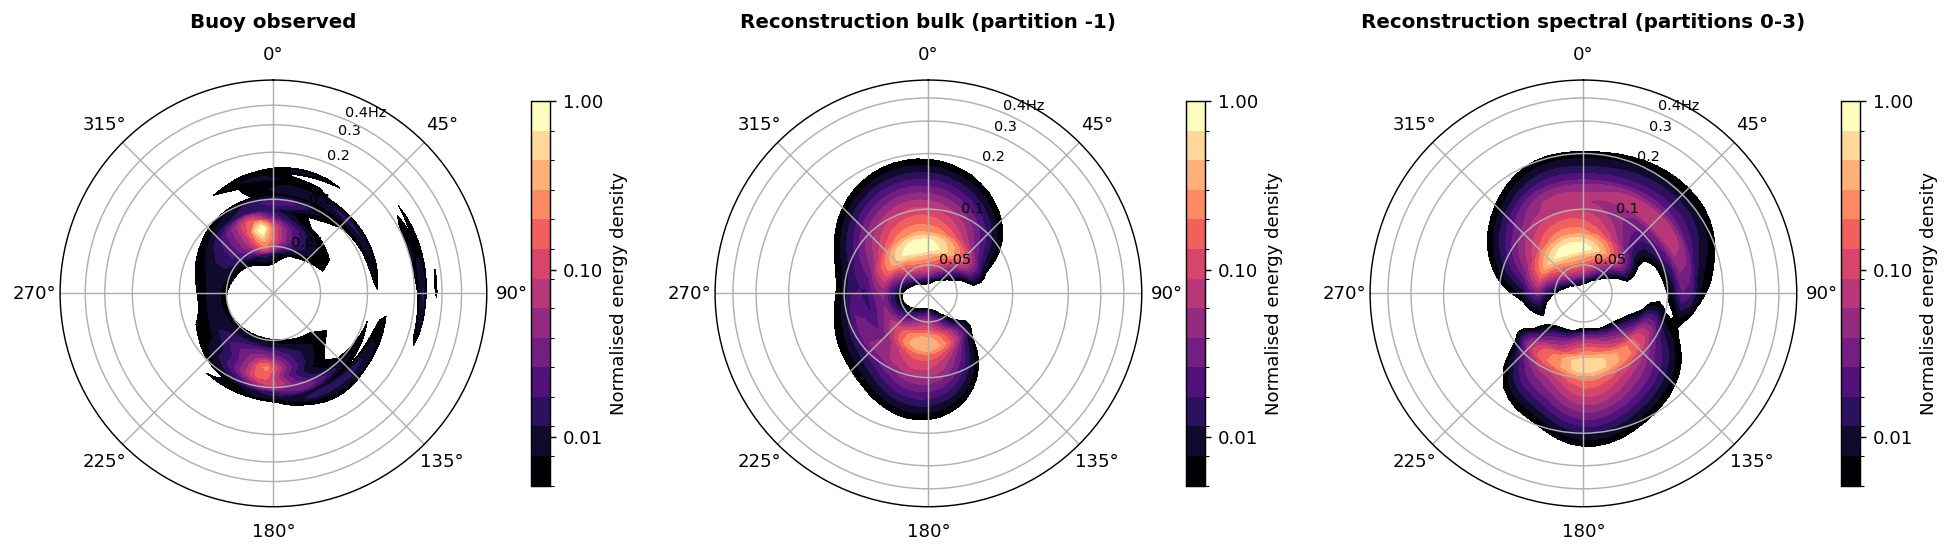

— buoy_Aunuu_Buoy — 2020-01-07T05 —


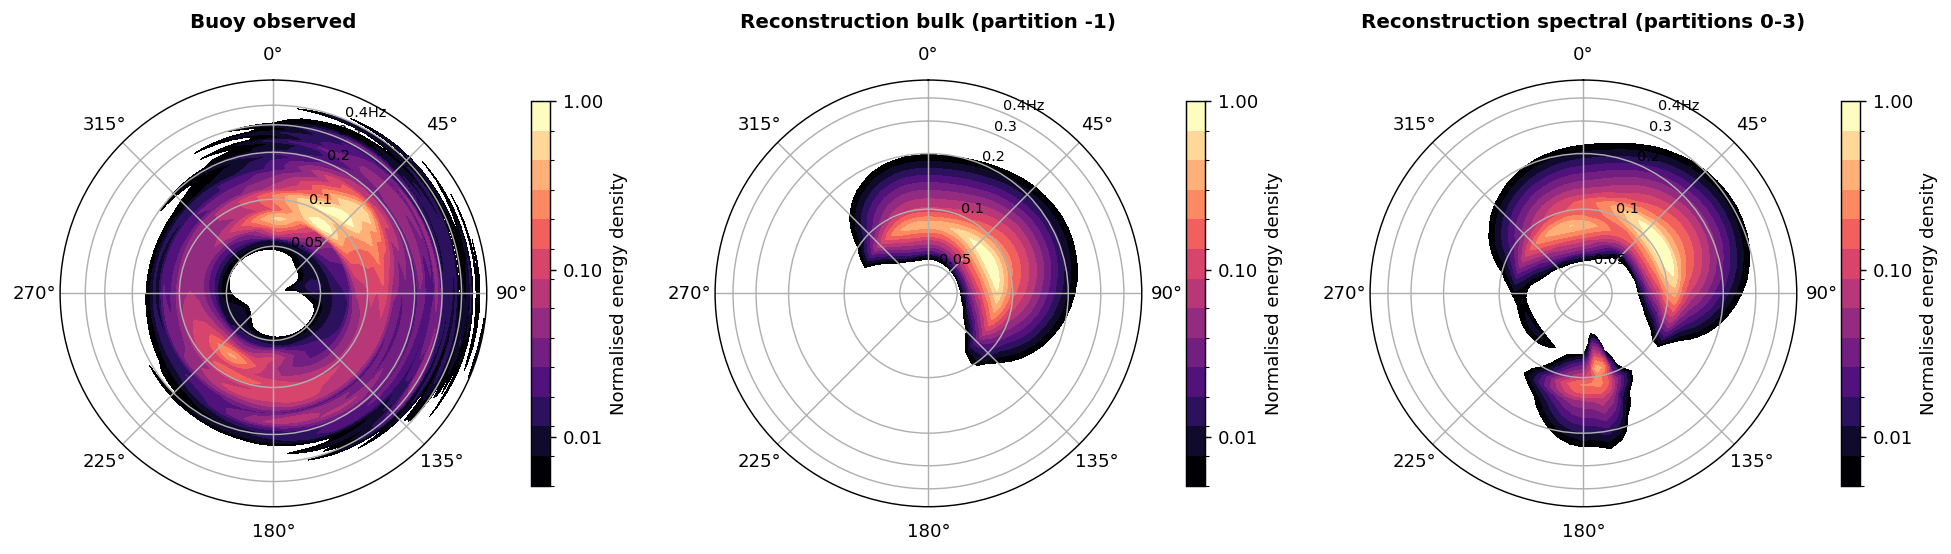

— buoy_Aunuu_Buoy — 2020-01-14T07 —


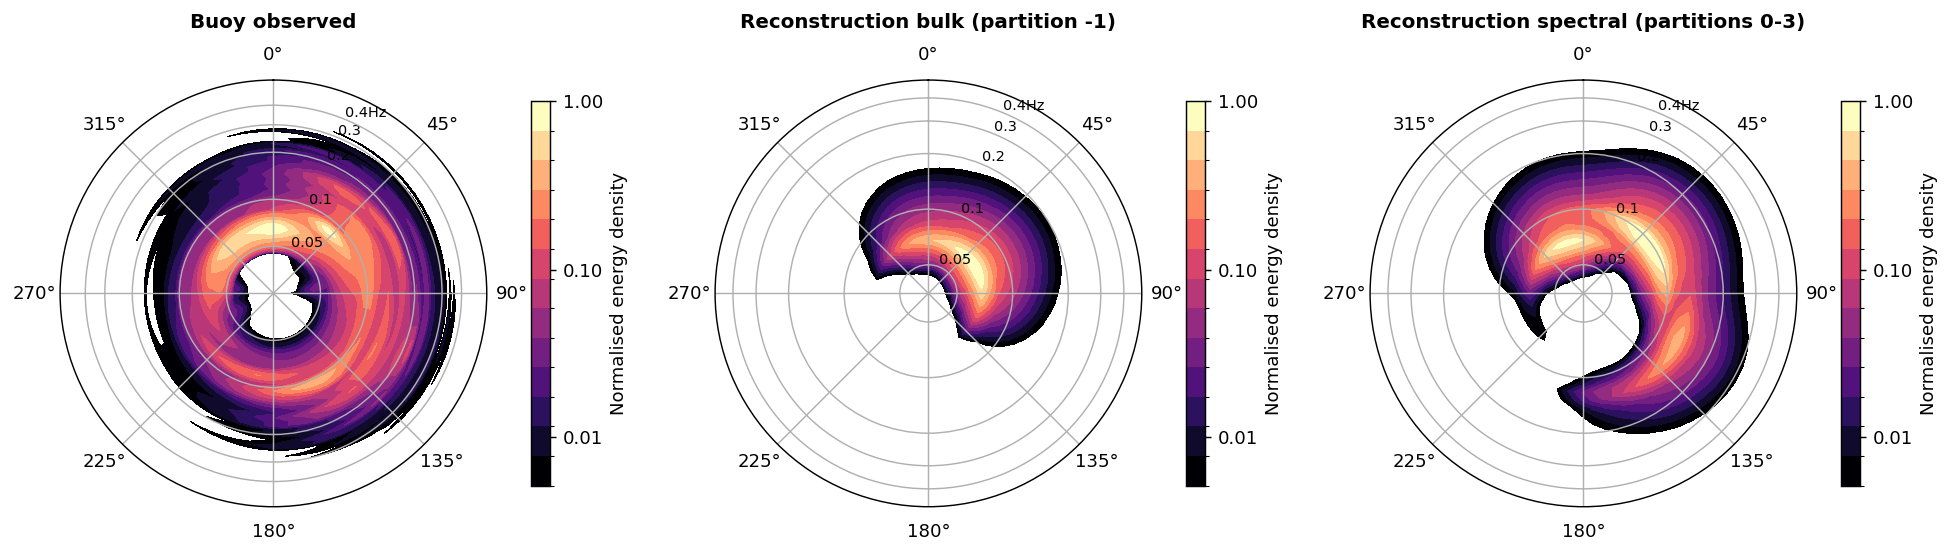

— buoy_Aunuu_Buoy — 2020-01-14T11 —


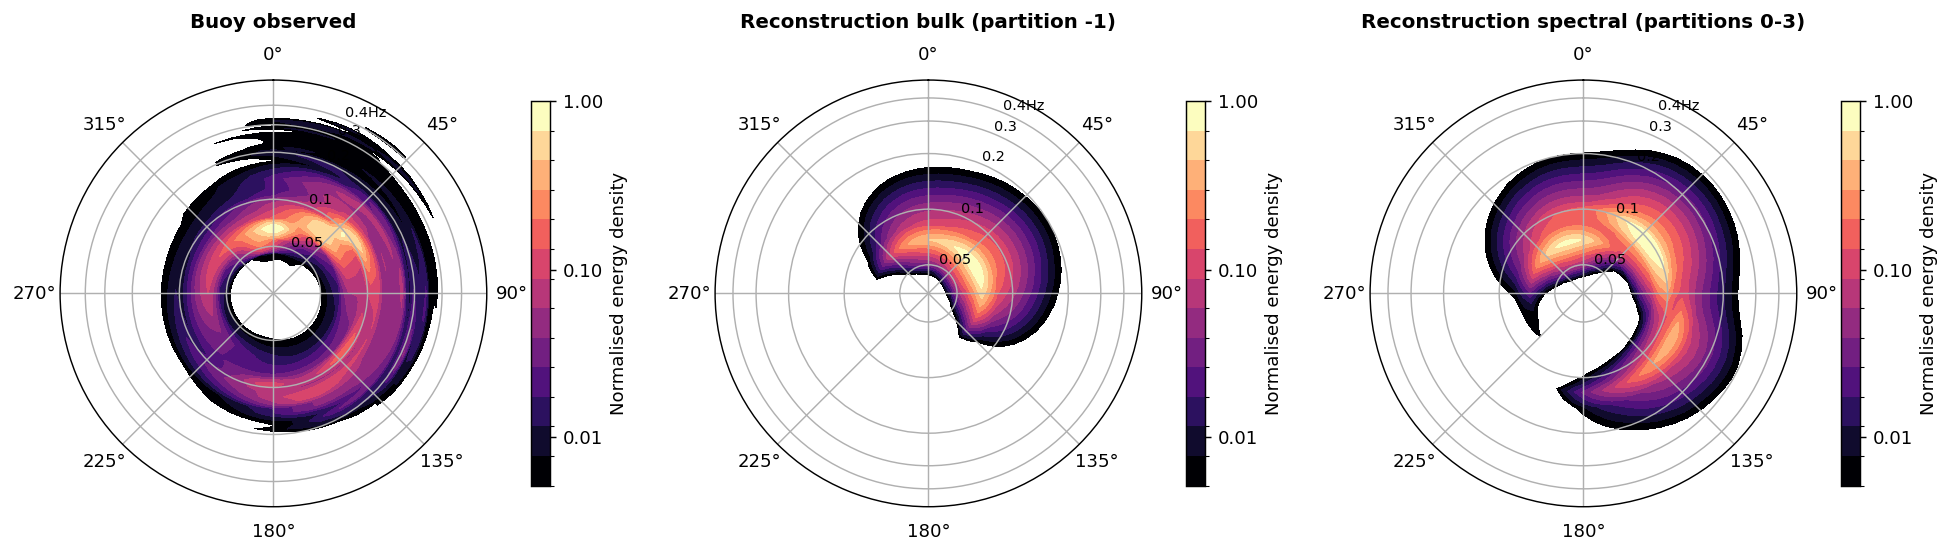

— buoy_Aunuu_Buoy — 2020-01-17T07 —


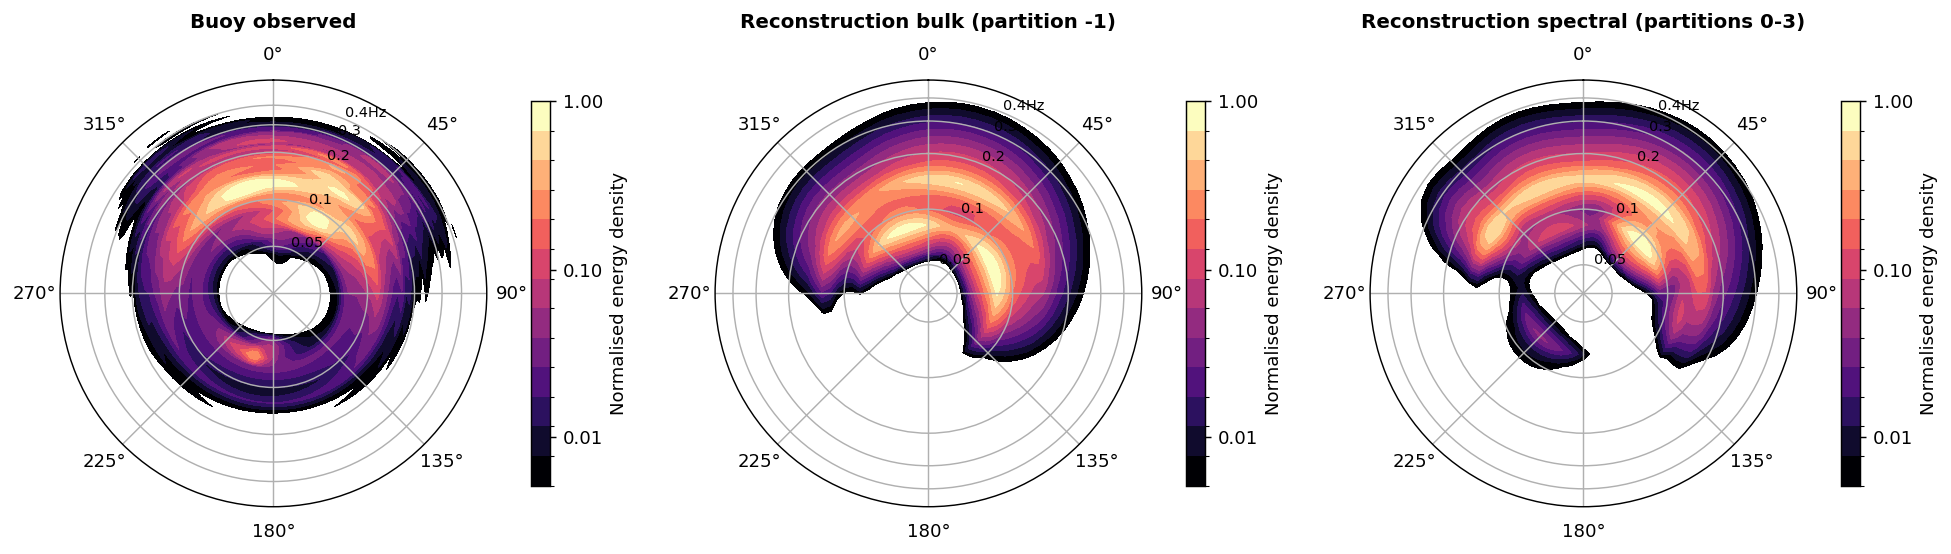

— buoy_Aunuu_Buoy — 2020-01-21T01 —


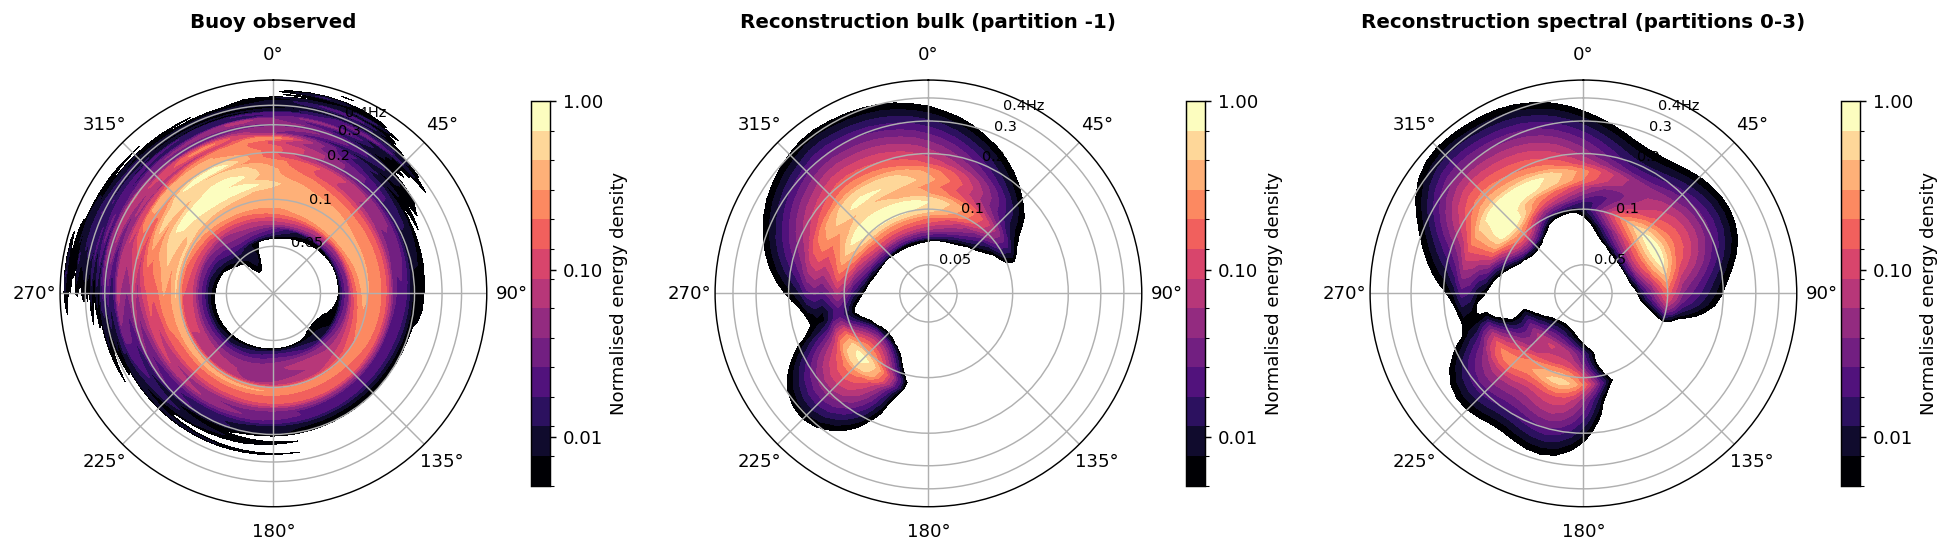

— buoy_Aunuu_Buoy — 2020-01-22T12 —


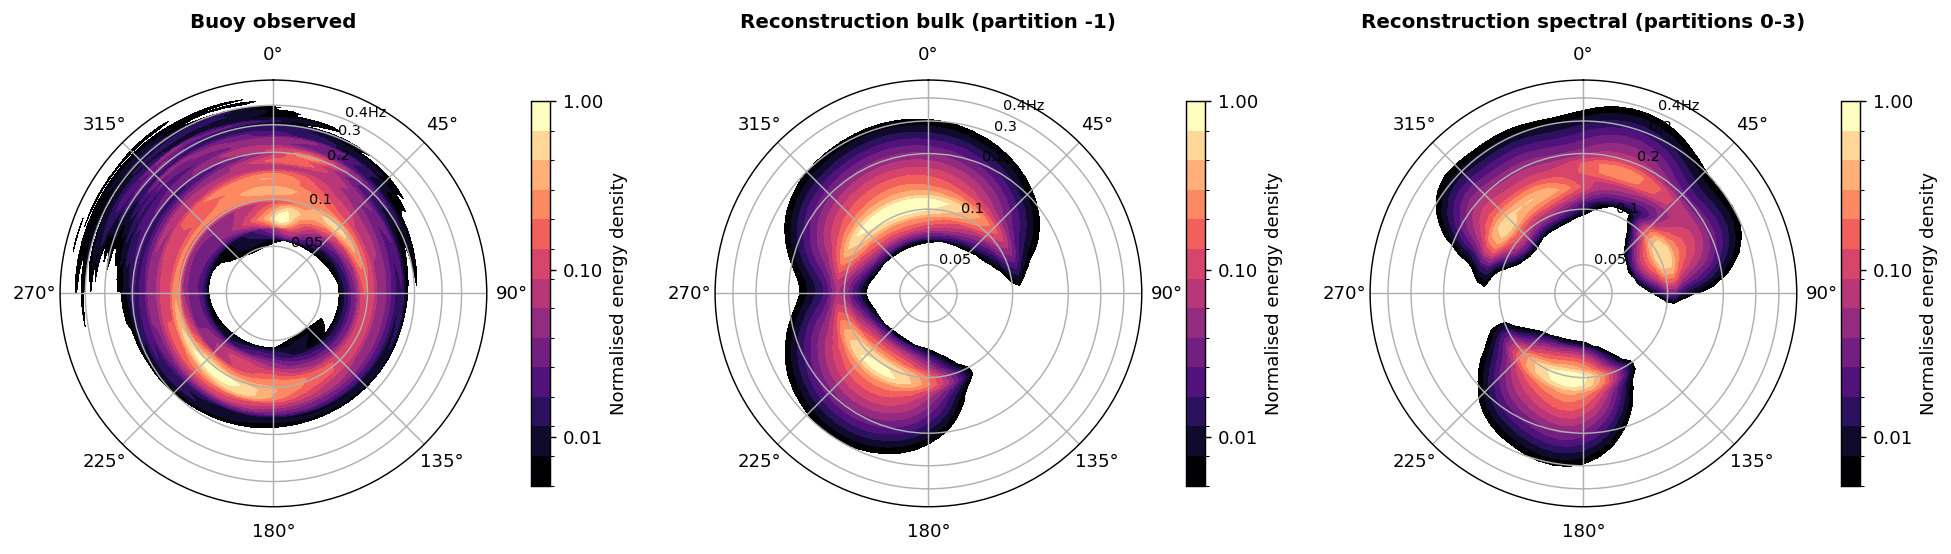

— buoy_Aunuu_Buoy — 2020-01-24T16 —


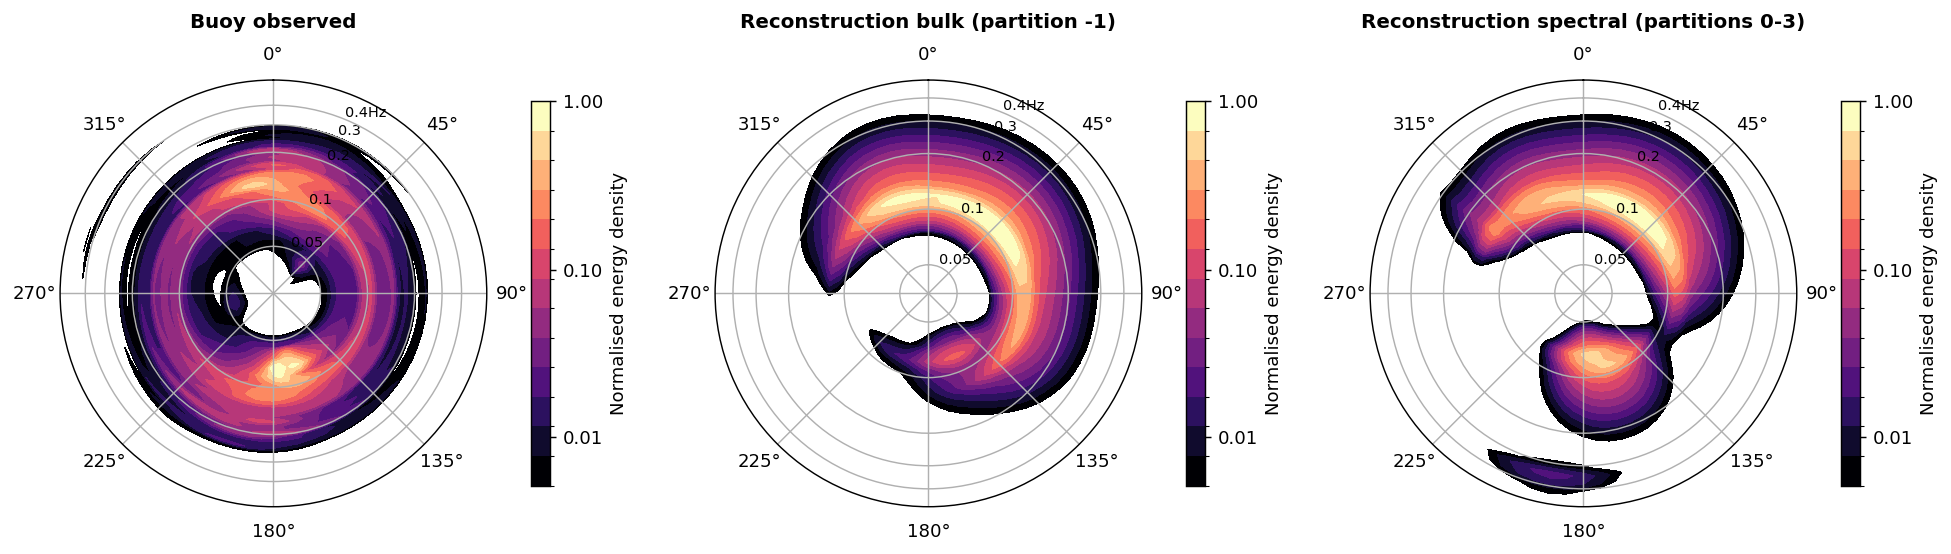

— buoy_Aunuu_Buoy — 2020-01-27T09 —


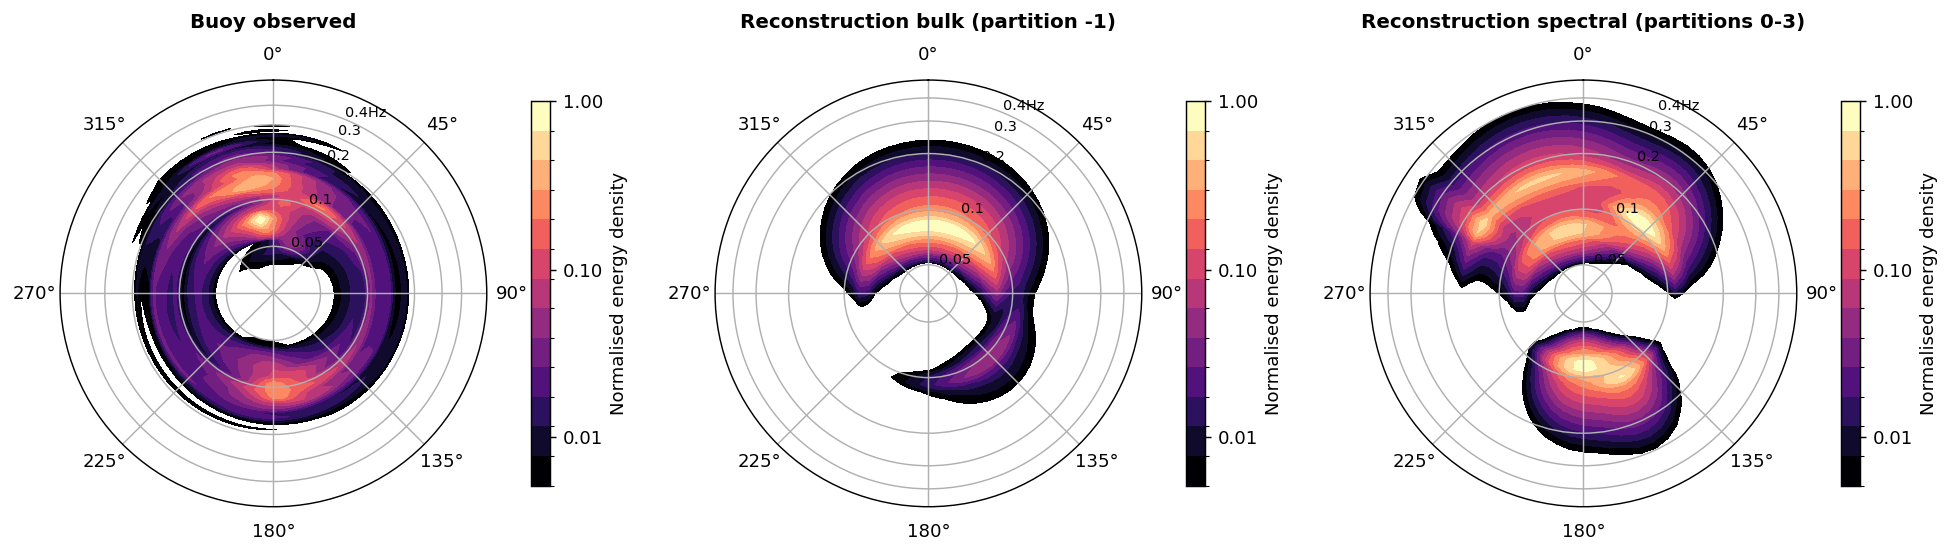

— buoy_Aunuu_Buoy — 2020-01-31T05 —


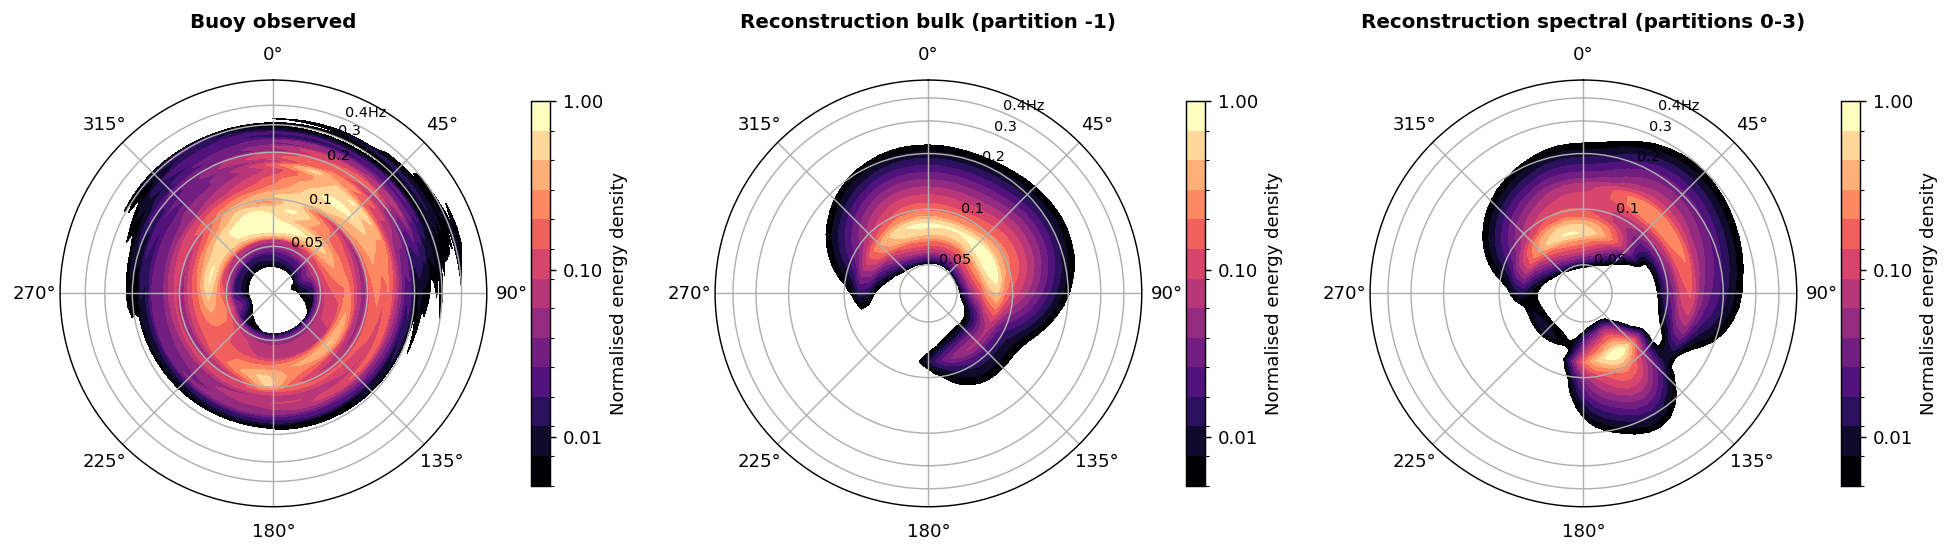

In [5]:
for i in range(sample_buoy.sizes["time"]):
    t = sample_buoy.time.values[i]
    show_triplet(
        sample_buoy.isel(time=i),
        sample_bulk.isel(time=i),
        sample_part.isel(time=i),
        f"{site_id} — {np.datetime_as_string(t, unit='h')}",
    )


## 4 · Monthly mean spectra

— buoy_Aunuu_Buoy — 2020-01 — month=1 —


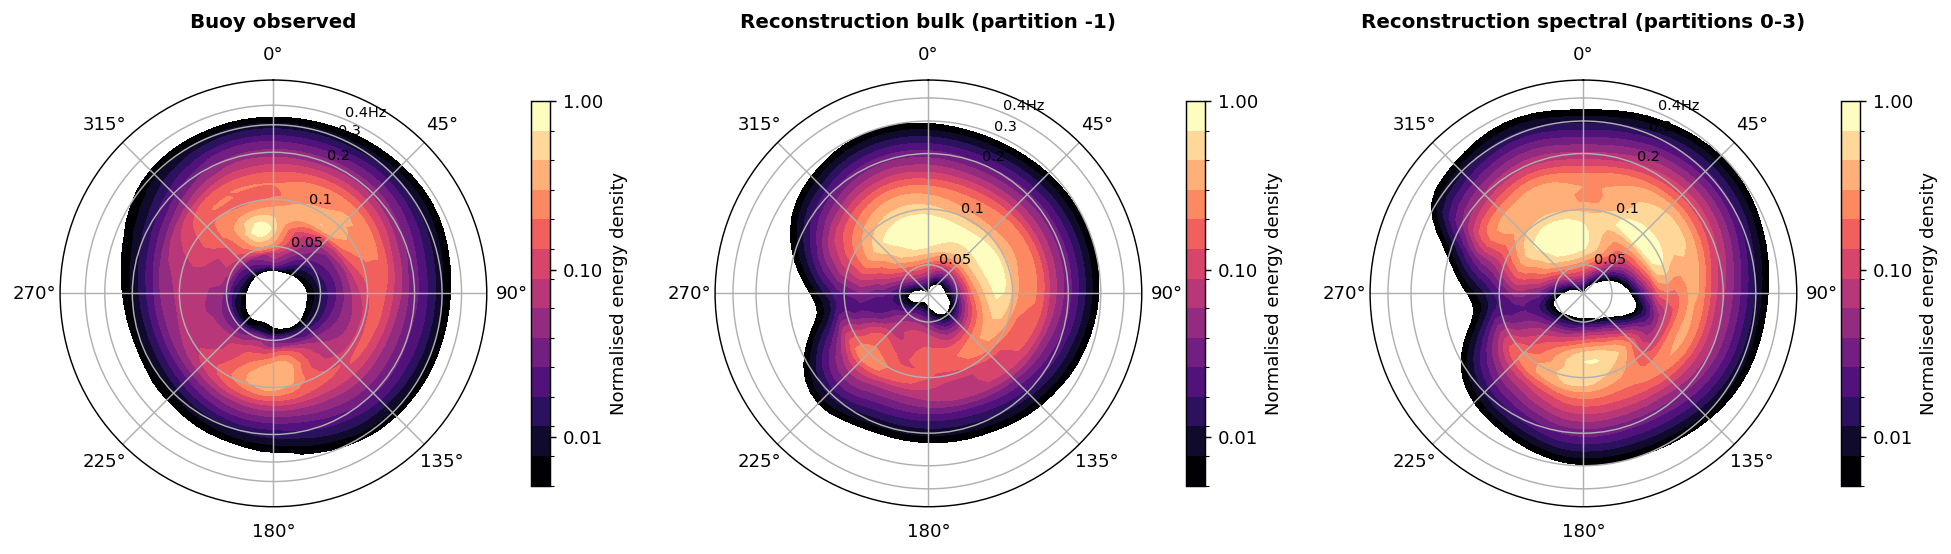

In [6]:
buoy_monthly = monthly_mean_spectra(buoy_efth.load())
bulk_monthly = monthly_mean_spectra(bulk_efth.load())
part_monthly = monthly_mean_spectra(part_efth.load())

# Buoy coverage is the limiting factor — walk its months, not the (always
# fully hourly) reconstruction's, and skip a source that has none for it.
for key in buoy_monthly:
    show_triplet(
        buoy_monthly[key],
        bulk_monthly.get(key),
        part_monthly.get(key),
        f"{site_id} — {period_label} — {key}",
    )


## 5 · Seasonal mean spectra

Meteorological seasons (`DJF`, `MAM`, …). For a single calendar month there is
typically one season in the sample.

— buoy_Aunuu_Buoy — 2020-01 — season=DJF —


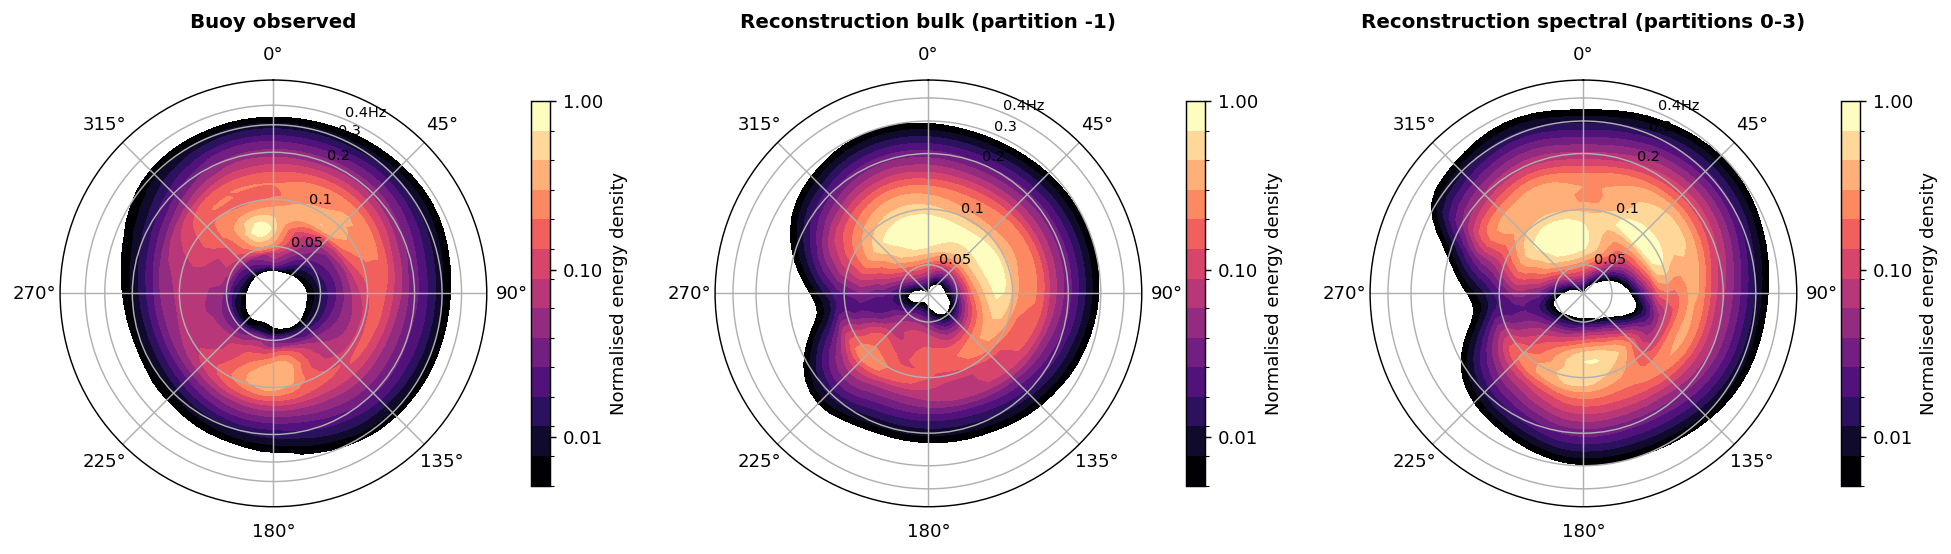

In [7]:
buoy_seasonal = seasonal_mean_spectra(buoy_efth)
bulk_seasonal = seasonal_mean_spectra(bulk_efth)
part_seasonal = seasonal_mean_spectra(part_efth)

for key in buoy_seasonal:
    show_triplet(
        buoy_seasonal[key],
        bulk_seasonal.get(key),
        part_seasonal.get(key),
        f"{site_id} — {period_label} — {key}",
    )
